# D5: validation of garment-cnn-v1 (evaluation notebook)

Tag `d5-v1`. Companion to `ANCP_TM_D5_v1.pdf`. The model is the Fashion-MNIST garment classifier of LLD 7.7 (`services/worker/models/garment-cnn-v1.onnx`).
Every number in the memo is written by the last cell to `evidence/d5_results.json`.

**Rules this notebook follows.** (1) It changes no model, threshold or setting; the test pictures are used to *report*, never to choose. (2) It reads only the four IDX files for scoring; the CSV files are read in one section, to show what the overlap does. (3) It prints plain text and PNG figures only (lint rule RL12).

**Needs** the Fashion-MNIST folder (`SPARTA_DATA_ROOT_MNIST` or `workflow/local.env`), `torch`, `onnxruntime`, `scipy`, `scikit-learn`, `matplotlib`, `pandas`, and `evidence/seed_*.json` written by `d5_seed_runs.py` (five retrainings; about 7 minutes each at 2 threads).

In [1]:
import json, hashlib, re, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import ndimage
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from PIL import Image
warnings.filterwarnings("ignore")

HERE = Path.cwd().resolve()
REPO = HERE.parents[1]                                   # notebook lives in submissions/D5
sys.path.insert(0, str(REPO / "ml" / "recommendation-engine" / "garment"))
import idx, preprocess as pp, train as T
from export_onnx import ONNX_PATH, session
import evaluate as ev

ROOT = idx.data_root()                                   # SPARTA_DATA_ROOT_MNIST or workflow/local.env
EVID = HERE / "evidence"; FIGS = HERE / "figs"; FIGS.mkdir(exist_ok=True)
CMAP = json.loads((REPO / "ml/recommendation-engine/garment/class_map.json").read_text())
NAMES = [CMAP[str(c)]["name"] for c in range(10)]
CATEGORY = [CMAP[str(c)]["category"] or "Dress (no mapping)" for c in range(10)]
MAPPED = np.array([CMAP[str(c)]["sub_type"] is not None for c in range(10)])
THR = 0.6                                                # GARMENT_MIN_CONFIDENCE default (LLD 7.7); not tuned here
SEED = 20261104                                          # seed of the released run (model card)
R = {}                                                   # everything the memo quotes
rng = np.random.default_rng(0)
print("torch", torch.__version__, "| ONNX", ONNX_PATH.name, ONNX_PATH.stat().st_size, "bytes")

torch 2.15.0 | ONNX garment-cnn-v1.onnx 105626 bytes


In [2]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return float(c - h), float(c + h)

BOOT_IDX = np.random.default_rng(1).integers(0, 10000, size=(2000, 10000))     # one fixed set of 2,000 resamples of the test pictures
def boot(per_picture):                                    # 95% percentile interval of a mean over test pictures
    v = BOOT_IDX_use(per_picture)
    return [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]
def BOOT_IDX_use(x): return np.asarray(x, dtype=float)[BOOT_IDX].mean(1)

def parts(pred, conf, y, thr=THR):
    """Per picture: hit (a correct suggestion is shown), wrong (a wrong one is shown), none (no suggestion)."""
    shown = (conf >= thr) & MAPPED[pred]
    return shown & (pred == y), shown & (pred != y), ~shown

def summary(pred, conf, y, thr=THR):
    hit, wrong, none = parts(pred, conf, y, thr); shown = hit | wrong
    return {"accuracy": float((pred == y).mean()), "macro_f1": float(f1_score(y, pred, average="macro")),
            "hit": float(hit.mean()), "wrong": float(wrong.mean()), "none": float(none.mean()),
            "precision_when_shown": float(hit.sum() / max(1, shown.sum())),
            "net100": {str(c): float(100 * (hit.mean() - c * wrong.mean())) for c in (1, 3, 10)}}

## 1. Data integrity and the split

In [3]:
hashes = ev.data_hashes(ROOT)                             # raises unless all four SHA-256 equal data/recommendation-engine/README.md
print("SHA-256 of the four IDX files equal the README values:", all(len(h) == 64 for h in hashes.values()))
Xtr, ytr = idx.load_split(ROOT, "train"); Xte, yte = idx.load_split(ROOT, "test")
yte = yte.astype(np.int64); ytr = ytr.astype(np.int64)
tr_i, va_i = T.stratified_split(ytr, 600, SEED)
print("train", len(tr_i), "validation", len(va_i), "test", len(Xte))
print("train/validation index overlap:", len(set(tr_i) & set(va_i)), "| validation per class:", np.bincount(ytr[va_i]).tolist())
print("test per class:", np.bincount(yte).tolist())
R["data"] = {"train": len(tr_i), "validation": len(va_i), "test": len(Xte), "overlap_train_val_index": len(set(tr_i) & set(va_i)),
             "sha_ok": True}

SHA-256 of the four IDX files equal the README values: True
train 54000 validation 6000 test 10000
train/validation index overlap: 0 | validation per class: [600, 600, 600, 600, 600, 600, 600, 600, 600, 600]
test per class: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


## 2. Leakage checks (evidence for the checklist)

In [4]:
# 2.1 exact pixel twins between the splits (IDX train vs IDX test, and validation vs training part)
h = lambda X: np.array([hashlib.sha1(x.tobytes()).hexdigest() for x in X])
Htr, Hte = h(Xtr), h(Xte)
tr_set = set(Htr)
twin_te = np.array([x in tr_set for x in Hte])
part_set = set(Htr[tr_i])
twin_va = np.array([x in part_set for x in Htr[va_i]])
print("IDX test pictures with an exact twin in the IDX training file:", int(twin_te.sum()), "of", len(Hte))
print("validation pictures with an exact twin in the 54,000 training part:", int(twin_va.sum()), "of", len(va_i))
print("duplicate pictures inside the IDX training file:", int(len(Htr) - len(tr_set)))
print("duplicate pictures inside the IDX test file:", int(len(Hte) - len(set(Hte))))
R["leak_exact"] = {"test_twin_in_train": int(twin_te.sum()), "val_twin_in_trainpart": int(twin_va.sum()),
                   "dups_in_train": int(len(Htr) - len(tr_set)), "dups_in_test": int(len(Hte) - len(set(Hte)))}

IDX test pictures with an exact twin in the IDX training file: 0 of 10000
validation pictures with an exact twin in the 54,000 training part: 0 of 6000
duplicate pictures inside the IDX training file: 0
duplicate pictures inside the IDX test file: 0


In [5]:
# 2.2 near-duplicates: nearest training picture for every test picture (pixel space, 0 to 1)
A = torch.from_numpy(Xtr.reshape(len(Xtr), -1).astype(np.float32) / 255); B = torch.from_numpy(Xte.reshape(len(Xte), -1).astype(np.float32) / 255)
an = (A * A).sum(1)
nn_d = []
for i in range(0, len(B), 1000):
    b = B[i:i + 1000]
    d2 = (b * b).sum(1, keepdim=True) + an[None, :] - 2 * b @ A.T
    nn_d.append(d2.min(1).values.clamp_min(0).sqrt())
nn_d = torch.cat(nn_d).numpy()
print("nearest-training-picture distance, quantiles 1/5/25/50/75%:", np.round(np.percentile(nn_d, [1, 5, 25, 50, 75]), 2).tolist())
print("test pictures closer than 1.0 to a training picture:", int((nn_d < 1.0).sum()), "| closer than 1.5:", int((nn_d < 1.5).sum()))
R["leak_near"] = {"q": np.round(np.percentile(nn_d, [1, 5, 25, 50, 75]), 2).tolist(), "lt1": int((nn_d < 1.0).sum()), "lt15": int((nn_d < 1.5).sum()), "min": float(nn_d.min())}
print("closest test picture to any training picture: %.2f" % nn_d.min())

nearest-training-picture distance, quantiles 1/5/25/50/75%: [1.55, 1.96, 2.79, 3.46, 4.27]
test pictures closer than 1.0 to a training picture: 16 | closer than 1.5: 82
closest test picture to any training picture: 0.08


In [6]:
# 2.3 the CSV copies versus the IDX files (what a wrong evaluation file would do), reproduces data README claim
csv_te = pd.read_csv(Path(ROOT) / "fashion-mnist_test.csv")
ycsv = csv_te["label"].to_numpy(np.int64); Xcsv = csv_te.drop(columns="label").to_numpy(np.uint8).reshape(-1, 28, 28)
Hcsv = h(Xcsv); te_set = set(Hte)
in_tr = np.array([x in tr_set for x in Hcsv]); in_te = np.array([x in te_set for x in Hcsv])
print("CSV test pictures found in the IDX training file:", int(in_tr.sum()), "| in the IDX test file:", int(in_te.sum()), "| of", len(Hcsv))
R["leak_csv"] = {"in_idx_train": int(in_tr.sum()), "in_idx_test": int(in_te.sum()), "n": int(len(Hcsv))}

CSV test pictures found in the IDX training file: 7919 | in the IDX test file: 1291 | of 10000


In [7]:
# 2.4 source checks: which files may read the test pictures, and what the training code does with them
src = (REPO / "ml/recommendation-engine/garment/train.py").read_text()
calls = re.findall(r'load_split\([^)]*\)', src)
print("train.py load_split calls:", calls)
print("train.py mentions the test split:", bool(re.search(r'load_split\([^)]*"test"', src)))
print("augment() is applied to training batches only:", "augment(x_tr[b]" in src and src.count("augment(") == 2)
print("preprocess.py has fitted statistics (mean/std/scaler):", bool(re.search(r'mean|std|scaler', (REPO / "ml/recommendation-engine/garment/preprocess.py").read_text(), re.I)))
print("model starts from pretrained weights:", bool(re.search(r'pretrained|load_state_dict\(torch.load', (REPO / "ml/recommendation-engine/garment/model.py").read_text())))
print(Path(REPO / "workflow/evidence/R5/tuning-notes.txt").read_text().splitlines()[0])
R["leak_src"] = {"train_calls": calls, "test_in_train": bool(re.search(r'load_split\([^)]*"test"', src))}

train.py load_split calls: ['load_split(root, "train")']
train.py mentions the test split: False
augment() is applied to training batches only: True
preprocess.py has fitted statistics (mean/std/scaler): False
model starts from pretrained weights: False
Settings were chosen on the 6,000-picture validation split only (the test pictures were never loaded by these runs).


## 3. The released model and the baselines on the 10,000 test pictures

In [8]:
sess = session(ONNX_PATH)
def run(X8):
    x = pp.normalise(X8); out = []
    for i in range(0, len(x), 1000): out.append(sess.run(["scores"], {"input": x[i:i + 1000]})[0])
    return np.concatenate(out)
P = run(Xte); pred = P.argmax(1); conf = P.max(1)
cnn = summary(pred, conf, yte)
corr = (pred == yte)
cnn["accuracy_ci"] = boot(corr); cnn["accuracy_wilson"] = wilson(int(corr.sum()), len(corr))
hit, wrong, none = parts(pred, conf, yte)
cnn["hit_ci"], cnn["wrong_ci"] = boot(hit), boot(wrong)
print("released model: accuracy %.4f  95%% CI %s  macro-F1 %.4f" % (cnn["accuracy"], np.round(cnn["accuracy_ci"], 4).tolist(), cnn["macro_f1"]))
print("per 100 photos at threshold %.1f: correct suggestion %.1f, wrong suggestion %.1f, no suggestion %.1f; precision when shown %.3f" % (THR, 100*cnn["hit"], 100*cnn["wrong"], 100*cnn["none"], cnn["precision_when_shown"]))
R["cnn"] = cnn

released model: accuracy 0.8953  95% CI [0.8891, 0.9012]  macro-F1 0.8953
per 100 photos at threshold 0.6: correct suggestion 73.7, wrong suggestion 3.6, no suggestion 22.7; precision when shown 0.954


In [9]:
# baselines: (a) always the most common class (= no suggestion ever reaches 0.6), (b) logistic regression on the 784 pixels, same 54,000 training pictures
maj = np.full(len(yte), np.bincount(ytr[tr_i]).argmax()); maj_conf = np.full(len(yte), 0.1)
base_maj = summary(maj, maj_conf, yte); base_maj["accuracy_ci"] = boot(maj == yte)
lr = LogisticRegression(max_iter=300).fit(Xtr[tr_i].reshape(len(tr_i), -1) / 255.0, ytr[tr_i])
Plr = lr.predict_proba(Xte.reshape(len(Xte), -1) / 255.0); plr = Plr.argmax(1); clr = Plr.max(1)
base_lr = summary(plr, clr, yte); base_lr["accuracy_ci"] = boot(plr == yte)
d = corr.astype(float) - (plr == yte).astype(float)
R["base_maj"], R["base_lr"] = base_maj, base_lr
R["cnn_minus_lr_accuracy"] = {"diff": float(d.mean()), "ci": boot(d)}
print("majority class: accuracy %.4f | logistic regression: accuracy %.4f, macro-F1 %.4f" % (base_maj["accuracy"], base_lr["accuracy"], base_lr["macro_f1"]))
print("logistic regression per 100: hit %.1f wrong %.1f none %.1f precision %.3f" % (100*base_lr["hit"], 100*base_lr["wrong"], 100*base_lr["none"], base_lr["precision_when_shown"]))
print("CNN minus logistic regression, accuracy: %.4f  95%% CI %s" % (d.mean(), np.round(boot(d), 4).tolist()))

majority class: accuracy 0.1000 | logistic regression: accuracy 0.8415, macro-F1 0.8408
logistic regression per 100: hit 70.2 wrong 7.7 none 22.1 precision 0.901
CNN minus logistic regression, accuracy: 0.0538  95% CI [0.0472, 0.0602]


In [10]:
# repeated runs: the same recipe, five seeds (seed changes split, initial weights, batch order and augmentation)
runs = []
for f in sorted(EVID.glob("seed_*.json")):
    r = json.loads(f.read_text()); p = np.array(r["pred"]); c = np.array(r["conf"])
    s = summary(p, c, yte); s.update(seed=r["seed"], val_accuracy=r["val_accuracy"], best_epoch=r["best_epoch"], stopped_by=r["stopped_by"]); runs.append(s)
    runs[-1]["per_class"] = [float((p[yte == k] == k).mean()) for k in range(10)]
print("seeds:", [r["seed"] for r in runs])
for k in ("accuracy", "macro_f1", "hit", "wrong", "precision_when_shown"):
    v = np.array([r[k] for r in runs]); print("%-22s mean %.4f  sd %.4f  min %.4f  max %.4f" % (k, v.mean(), v.std(ddof=1), v.min(), v.max()))
main = [r for r in runs if r["seed"] == SEED][0]
print("released-seed rerun: validation %.4f (model card 0.8983), test %.4f (ONNX %.4f)" % (main["val_accuracy"], main["accuracy"], cnn["accuracy"]))
R["runs"] = {"seeds": [r["seed"] for r in runs], "n": len(runs),
             **{k: {"mean": float(np.mean([r[k] for r in runs])), "sd": float(np.std([r[k] for r in runs], ddof=1)),
                    "min": float(min(r[k] for r in runs)), "max": float(max(r[k] for r in runs))} for k in ("accuracy", "macro_f1", "hit", "wrong", "precision_when_shown")},
             "per_class_sd": [float(np.std([r["per_class"][k] for r in runs], ddof=1)) for k in range(10)],
             "per_class_mean": [float(np.mean([r["per_class"][k] for r in runs])) for k in range(10)],
             "net100": {c: {"mean": float(np.mean([r["net100"][c] for r in runs])), "sd": float(np.std([r["net100"][c] for r in runs], ddof=1))} for c in ("1", "3", "10")},
             "release_seed_val": main["val_accuracy"], "release_seed_test": main["accuracy"], "stopped_by": sorted({r["stopped_by"] for r in runs})}

seeds: [1, 2, 20261104, 3, 4]
accuracy               mean 0.8953  sd 0.0028  min 0.8918  max 0.8992
macro_f1               mean 0.8951  sd 0.0028  min 0.8915  max 0.8987
hit                    mean 0.7356  sd 0.0092  min 0.7232  max 0.7465
wrong                  mean 0.0365  sd 0.0016  min 0.0355  max 0.0393
precision_when_shown   mean 0.9527  sd 0.0017  min 0.9500  max 0.9543
released-seed rerun: validation 0.8983 (model card 0.8983), test 0.8953 (ONNX 0.8953)


In [11]:
# what the wrong evaluation file would have reported: the released model scored on the CSV test pictures
Pc = run(Xcsv); okc = Pc.argmax(1) == ycsv
print("accuracy on the 10,000 CSV test pictures: %.4f (IDX test: %.4f)" % (okc.mean(), corr.mean()))
print("  on the %d that are also IDX training pictures: %.4f | on the other %d: %.4f" % (in_tr.sum(), okc[in_tr].mean(), (~in_tr).sum(), okc[~in_tr].mean()))
R["leak_csv"].update(acc_csv=float(okc.mean()), acc_csv_seen=float(okc[in_tr].mean()), acc_csv_unseen=float(okc[~in_tr].mean()))

accuracy on the 10,000 CSV test pictures: 0.9066 (IDX test: 0.8953)
  on the 7919 that are also IDX training pictures: 0.9098 | on the other 2081: 0.8943


## 4. Cost of errors: thresholds and net benefit

In [12]:
rows = []
for t in (0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
    hi, wr, no = parts(pred, conf, yte, t); sh = hi | wr
    rows.append({"thr": t, "hit": 100 * hi.mean(), "wrong": 100 * wr.mean(), "none": 100 * no.mean(), "precision": float(hi.sum() / max(1, sh.sum())),
                 **{"net_c%d" % c: 100 * (hi.mean() - c * wr.mean()) for c in (1, 3, 10)}})
print(pd.DataFrame(rows).round(3).to_string(index=False))
R["threshold_sweep"] = rows
# break-even precision for a cost ratio c (a wrong suggestion costs c correct ones): c / (1 + c)
print({c: round(c / (1 + c), 3) for c in (1, 3, 10)})
# calibration of the top score
bins = np.linspace(0, 1, 11); ece = 0.0; cal = []
for lo, hi_ in zip(bins[:-1], bins[1:]):
    m = (conf > lo) & (conf <= hi_)
    if m.sum(): ece += m.mean() * abs(corr[m].mean() - conf[m].mean()); cal.append((round(lo, 1), int(m.sum()), round(float(conf[m].mean()), 3), round(float(corr[m].mean()), 3)))
print("expected calibration error: %.4f" % ece); print("bins (low, n, mean score, accuracy):", cal)
R["ece"] = float(ece); R["calibration"] = cal

 thr   hit  wrong  none  precision  net_c1  net_c3  net_c10
 0.4 79.79   7.76 12.45      0.911   72.03   56.51     2.19
 0.5 77.42   5.59 16.99      0.933   71.83   60.65    21.52
 0.6 73.70   3.56 22.74      0.954   70.14   63.02    38.10
 0.7 68.47   2.10 29.43      0.970   66.37   62.17    47.47
 0.8 60.88   0.93 38.19      0.985   59.95   58.09    51.58
 0.9 39.17   0.15 60.68      0.996   39.02   38.72    37.67
{1: 0.5, 3: 0.75, 10: 0.909}
expected calibration error: 0.0847
bins (low, n, mean score, accuracy): [(np.float64(0.1), 1, 0.199, 0.0), (np.float64(0.2), 53, 0.27, 0.226), (np.float64(0.3), 197, 0.36, 0.401), (np.float64(0.4), 512, 0.457, 0.521), (np.float64(0.5), 649, 0.549, 0.649), (np.float64(0.6), 757, 0.65, 0.771), (np.float64(0.7), 989, 0.754, 0.862), (np.float64(0.8), 2525, 0.862, 0.966), (np.float64(0.9), 4317, 0.931, 0.996)]


## 5. Error analysis

largest confusions: [('Shirt', 'T-shirt/top', 124), ('T-shirt/top', 'Shirt', 103), ('Shirt', 'Coat', 82), ('Coat', 'Shirt', 70), ('Pullover', 'Coat', 64), ('Pullover', 'Shirt', 59)]
      class  recall  precision
T-shirt/top   0.835      0.844
    Trouser   0.969      0.995
   Pullover   0.852      0.864
      Dress   0.895      0.865
       Coat   0.832      0.821
     Sandal   0.966      0.985
      Shirt   0.700      0.707
    Sneaker   0.966      0.938
        Bag   0.977      0.972
 Ankle boot   0.961      0.965
all errors: 1047 within one category 473 across categories 574
wrong suggestions shown at 0.6: 356 within category 199 across categories 157
true Dress pictures (can never receive a suggestion): 1000 | of them shown as another garment: 32
errors made with top score >= 0.9: 18 | with >= 0.6: 414


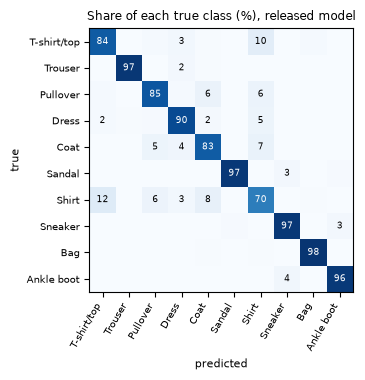

In [13]:
cm = np.zeros((10, 10), int); np.add.at(cm, (yte, pred), 1)
off = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)[:6]
print("largest confusions:", [(NAMES[i], NAMES[j], int(n)) for n, i, j in off])
prec = cm.diagonal() / cm.sum(0); rec = cm.diagonal() / cm.sum(1)
print(pd.DataFrame({"class": NAMES, "recall": rec.round(3), "precision": prec.round(3)}).to_string(index=False))
cat = np.array(CATEGORY)
err = pred != yte
within = int((err & (cat[pred] == cat[yte])).sum()); cross = int((err & (cat[pred] != cat[yte])).sum())
hi_, wr_, _ = parts(pred, conf, yte)
w_within = int((wr_ & (cat[pred] == cat[yte])).sum()); w_cross = int((wr_ & (cat[pred] != cat[yte])).sum())
print("all errors:", int(err.sum()), "within one category", within, "across categories", cross)
print("wrong suggestions shown at 0.6:", int(wr_.sum()), "within category", w_within, "across categories", w_cross)
dress_missing = int((yte == 3).sum())
print("true Dress pictures (can never receive a suggestion):", dress_missing, "| of them shown as another garment:", int((wr_ & (yte == 3)).sum()))
hc = np.flatnonzero(err & (conf >= 0.9))
print("errors made with top score >= 0.9:", len(hc), "| with >= 0.6:", int((err & (conf >= 0.6)).sum()))
R["errors"] = {"confusion": cm.tolist(), "top": [[NAMES[i], NAMES[j], int(n)] for n, i, j in off], "recall": rec.round(4).tolist(), "precision": prec.round(4).tolist(),
               "err_total": int(err.sum()), "err_within": within, "err_cross": cross, "wrong_shown": int(wr_.sum()), "wrong_within": w_within, "wrong_cross": w_cross,
               "dress_n": dress_missing, "dress_wrong_shown": int((wr_ & (yte == 3)).sum()), "err_conf90": int(len(hc)), "err_conf60": int((err & (conf >= 0.6)).sum())}
fig, ax = plt.subplots(figsize=(4.6, 3.9)); n = cm / cm.sum(1, keepdims=True)
ax.imshow(n, cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        if n[i, j] >= 0.015: ax.text(j, i, "%d" % round(100 * n[i, j]), ha="center", va="center", fontsize=6.5, color="white" if n[i, j] > 0.5 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(NAMES, rotation=60, ha="right", fontsize=7); ax.set_yticklabels(NAMES, fontsize=7)
ax.set_xlabel("predicted", fontsize=8); ax.set_ylabel("true", fontsize=8); ax.set_title("Share of each true class (%), released model", fontsize=8.5)
fig.tight_layout(); fig.savefig(FIGS / "fig_confusion.png", dpi=200); plt.show()

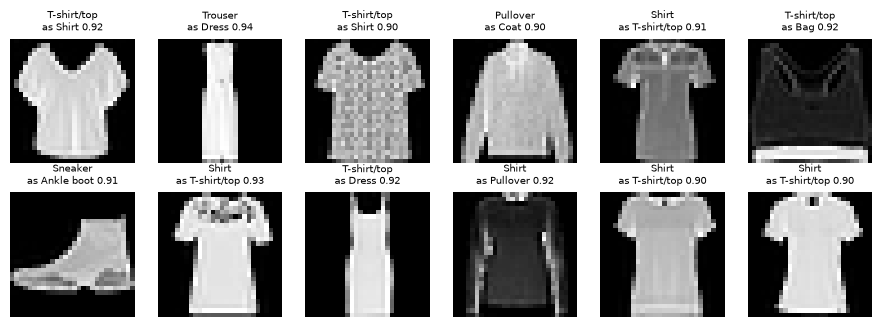

In [14]:
# the high-confidence mistakes, as pictures (for the notebook; garment pictures only, no personal data)
pick = np.flatnonzero(err & (conf >= 0.9))[:12]
fig, axs = plt.subplots(2, 6, figsize=(9, 3.3))
for a, k in zip(axs.ravel(), pick):
    a.imshow(Xte[k], cmap="gray"); a.set_title("%s\nas %s %.2f" % (NAMES[yte[k]], NAMES[pred[k]], conf[k]), fontsize=7); a.axis("off")
fig.tight_layout(); plt.show()

## 6. Robustness: perturbations of the test pictures (released model, no retraining)

In [15]:
def geo(X, ang=0.0, sc=1.0, tx=0.0, ty=0.0):
    x = torch.from_numpy(X.astype(np.float32) / 255)[:, None]; n = len(x); a = np.deg2rad(ang)
    th = torch.tensor([[np.cos(a) / sc, -np.sin(a) / sc, tx / 14], [np.sin(a) / sc, np.cos(a) / sc, ty / 14]], dtype=torch.float32).repeat(n, 1, 1)
    g = torch.nn.functional.grid_sample(x, torch.nn.functional.affine_grid(th, list(x.shape), align_corners=False), padding_mode="zeros", align_corners=False)
    return np.clip(np.rint(g[:, 0].numpy() * 255), 0, 255).astype(np.uint8)
def noise(X, s): return np.clip(np.rint(X + np.random.default_rng(7).normal(0, s, X.shape)), 0, 255).astype(np.uint8)
def occlude(X, k):
    r = np.random.default_rng(8); Y = X.copy()
    for i in range(len(Y)):
        y0, x0 = r.integers(0, 28 - k + 1, 2); Y[i, y0:y0 + k, x0:x0 + k] = 0
    return Y
PERT = [("intensity x0.5 (light garment)", lambda X: np.rint(X * 0.5).astype(np.uint8)),
        ("intensity x0.3 (very faint)", lambda X: np.rint(X * 0.3).astype(np.uint8)),
        ("background haze +30", lambda X: np.clip(X.astype(int) + 30, 0, 255).astype(np.uint8)),
        ("noise sd 10", lambda X: noise(X, 10)), ("noise sd 25", lambda X: noise(X, 25)),
        ("blur sd 1 px", lambda X: np.rint(ndimage.gaussian_filter(X.astype(np.float32), sigma=(0, 1, 1))).astype(np.uint8)),
        ("shift 2 px", lambda X: geo(X, tx=2, ty=-2)), ("shift 4 px", lambda X: geo(X, tx=4, ty=-4)),
        ("rotate 15 deg", lambda X: geo(X, ang=15)), ("rotate 30 deg", lambda X: geo(X, ang=30)),
        ("scale 0.8 (smaller)", lambda X: geo(X, sc=0.8)), ("scale 1.2 (larger)", lambda X: geo(X, sc=1.2)),
        ("hide 8x8 patch", lambda X: occlude(X, 8)), ("hide 12x12 patch", lambda X: occlude(X, 12)),
        ("mirror left-right", lambda X: X[:, :, ::-1].copy()),
        ("polarity wrong (not inverted)", lambda X: 255 - X)]
rob = []
for name, f in PERT:
    Pp = run(f(Xte)); pp_ = Pp.argmax(1); cc = Pp.max(1); ok = (pp_ == yte)
    dlt = ok.astype(float) - corr.astype(float); hi2, wr2, no2 = parts(pp_, cc, yte)
    rob.append({"name": name, "accuracy": float(ok.mean()), "delta": float(dlt.mean()), "delta_ci": boot(dlt), "hit": float(100 * hi2.mean()), "wrong": float(100 * wr2.mean()), "none": float(100 * no2.mean())})
print(pd.DataFrame(rob)[["name", "accuracy", "delta", "hit", "wrong", "none"]].round(3).to_string(index=False))
R["robust"] = rob
mir = run(Xte[:, :, ::-1].copy()).argmax(1)       # which classes lose accuracy when the picture is mirrored
R["mirror_per_class"] = {NAMES[k]: [float((pred[yte == k] == k).mean()), float((mir[yte == k] == k).mean())] for k in range(10)}
print("accuracy per class, normal vs mirrored:", {k: [round(x, 3) for x in v] for k, v in R["mirror_per_class"].items()})

                          name  accuracy  delta   hit  wrong  none
intensity x0.5 (light garment)     0.833 -0.062 66.89   7.44 25.67
   intensity x0.3 (very faint)     0.753 -0.142 54.82   9.23 35.95
           background haze +30     0.889 -0.007 71.68   3.61 24.71
                   noise sd 10     0.859 -0.036 64.81   4.10 31.09
                   noise sd 25     0.730 -0.166 42.18   5.86 51.96
                  blur sd 1 px     0.863 -0.032 67.82   3.91 28.27
                    shift 2 px     0.853 -0.042 65.28   3.86 30.86
                    shift 4 px     0.742 -0.153 42.25   3.20 54.55
                 rotate 15 deg     0.820 -0.076 56.76   3.52 39.72
                 rotate 30 deg     0.450 -0.446 16.83   8.17 75.00
           scale 0.8 (smaller)     0.816 -0.079 57.42   3.92 38.66
            scale 1.2 (larger)     0.826 -0.069 65.49   6.21 28.30
                hide 8x8 patch     0.834 -0.062 60.68   4.26 35.06
              hide 12x12 patch     0.673 -0.222 37.64   6.22 5

accuracy per class, normal vs mirrored: {'T-shirt/top': [0.835, 0.824], 'Trouser': [0.969, 0.966], 'Pullover': [0.852, 0.821], 'Dress': [0.895, 0.893], 'Coat': [0.832, 0.844], 'Sandal': [0.966, 0.469], 'Shirt': [0.7, 0.686], 'Sneaker': [0.966, 0.319], 'Bag': [0.977, 0.969], 'Ankle boot': [0.961, 0.0]}


pipeline round trip: unusable cut-outs 0 | accuracy 0.8927 (clean 0.8953) change -0.0026 CI [-0.0063, 0.0008]


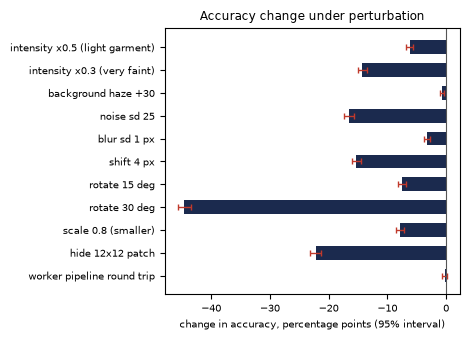

In [16]:
# the worker's own preprocessing (LLD 7.7 steps 1 to 6) applied to a synthetic cut-out made from each test picture: checks for train/serve skew
def cutout(img28, side=224):
    g = np.asarray(Image.fromarray(img28).resize((side, side), Image.Resampling.BICUBIC))
    alpha = np.where(g > 12, 255, 0).astype(np.uint8)
    return np.dstack([np.repeat((255 - g)[..., None], 3, axis=2), alpha])
rt = np.zeros_like(Xte); bad = 0
for i in range(len(Xte)):
    try: rt[i] = (pp.preprocess(cutout(Xte[i]))[0, 0] * 255).round().astype(np.uint8)
    except ValueError: rt[i] = 0; bad += 1
Prt = run(rt); prt = Prt.argmax(1); okr = prt == yte
dlt = okr.astype(float) - corr.astype(float); hi3, wr3, no3 = parts(prt, Prt.max(1), yte)
print("pipeline round trip: unusable cut-outs %d | accuracy %.4f (clean %.4f) change %.4f CI %s" % (bad, okr.mean(), corr.mean(), dlt.mean(), np.round(boot(dlt), 4).tolist()))
R["roundtrip"] = {"bad": bad, "accuracy": float(okr.mean()), "delta": float(dlt.mean()), "delta_ci": boot(dlt), "hit": float(100*hi3.mean()), "wrong": float(100*wr3.mean()), "none": float(100*no3.mean())}
sel = [r for r in rob if r["name"] in ("intensity x0.5 (light garment)", "intensity x0.3 (very faint)", "background haze +30", "noise sd 25", "blur sd 1 px", "shift 4 px", "rotate 15 deg", "rotate 30 deg", "scale 0.8 (smaller)", "hide 12x12 patch")]
sel.append({"name": "worker pipeline round trip", **{k: R["roundtrip"][k] for k in ("delta", "delta_ci")}})
fig, ax = plt.subplots(figsize=(4.8, 3.5)); y = np.arange(len(sel))[::-1]
ax.barh(y, [100 * r["delta"] for r in sel], color="#1b2a4e", height=0.6)
ax.errorbar([100 * r["delta"] for r in sel], y, xerr=[[100 * (r["delta"] - r["delta_ci"][0]) for r in sel], [100 * (r["delta_ci"][1] - r["delta"]) for r in sel]], fmt="none", ecolor="#c0392b", capsize=2, lw=1)
ax.set_yticks(y); ax.set_yticklabels([r["name"] for r in sel], fontsize=7); ax.tick_params(axis="x", labelsize=7)
ax.axvline(0, color="#555", lw=0.8); ax.set_xlabel("change in accuracy, percentage points (95% interval)", fontsize=7.5); ax.set_title("Accuracy change under perturbation", fontsize=8.5)
fig.tight_layout(); fig.savefig(FIGS / "fig_robust.png", dpi=200); plt.show()

## 7. Subgroups

In [17]:
ink = np.array([x[x > 0].mean() if (x > 0).any() else 0 for x in Xte]); area = (Xte > 0).reshape(len(Xte), -1).mean(1)
def tercile_within_class(v):                              # 0 low, 1 mid, 2 high, ranked inside each class so every group has the same class mix
    out = np.zeros(len(v), int)
    for k in range(10):
        m = np.flatnonzero(yte == k); q = np.quantile(v[m], [1/3, 2/3]); out[m] = np.digitize(v[m], q)
    return out
tb, ta = tercile_within_class(ink), tercile_within_class(area)
def grp(mask):
    n = int(mask.sum()); k = int(corr[mask].sum()); hh, ww, _ = parts(pred[mask], conf[mask], yte[mask])
    return {"n": n, "accuracy": k / n, "ci": list(wilson(k, n)), "wrong100": float(100 * ww.mean())}
sub = {"class": {NAMES[k]: grp(yte == k) for k in range(10)},
       "category": {c: grp(cat[yte] == c) for c in sorted(set(CATEGORY))},
       "brightness": {n_: grp(tb == i) for i, n_ in enumerate(("faint third", "middle third", "bright third"))},
       "size": {n_: grp(ta == i) for i, n_ in enumerate(("small third", "middle third", "large third"))}}
for g_, d_ in sub.items():
    print(g_); [print("   %-18s n %5d  acc %.3f  CI %.3f-%.3f  wrong-shown/100 %.1f" % (k, v["n"], v["accuracy"], *v["ci"], v["wrong100"])) for k, v in d_.items()]
R["subgroups"] = sub

class
   T-shirt/top        n  1000  acc 0.835  CI 0.811-0.857  wrong-shown/100 4.8
   Trouser            n  1000  acc 0.969  CI 0.956-0.978  wrong-shown/100 0.3
   Pullover           n  1000  acc 0.852  CI 0.829-0.873  wrong-shown/100 5.4
   Dress              n  1000  acc 0.895  CI 0.874-0.913  wrong-shown/100 3.2
   Coat               n  1000  acc 0.832  CI 0.808-0.854  wrong-shown/100 4.5
   Sandal             n  1000  acc 0.966  CI 0.953-0.976  wrong-shown/100 1.7
   Shirt              n  1000  acc 0.700  CI 0.671-0.728  wrong-shown/100 11.5
   Sneaker            n  1000  acc 0.966  CI 0.953-0.976  wrong-shown/100 1.4
   Bag                n  1000  acc 0.977  CI 0.966-0.985  wrong-shown/100 0.0
   Ankle boot         n  1000  acc 0.961  CI 0.947-0.971  wrong-shown/100 2.8
category
   Accessories        n  1000  acc 0.977  CI 0.966-0.985  wrong-shown/100 0.0
   Bottoms            n  1000  acc 0.969  CI 0.956-0.978  wrong-shown/100 0.3
   Dress (no mapping) n  1000  acc 0.895  CI 0.8

## 8. Results file for the memo

In [18]:
R["meta"] = {"threshold": THR, "release_seed": SEED, "onnx_sha256": ev.sha256_file(ONNX_PATH), "torch": torch.__version__,
             "numpy": np.__version__, "bootstrap": "2,000 resamples of the 10,000 test pictures, seed 1, percentile 2.5 to 97.5"}
(EVID / "d5_results.json").write_text(json.dumps(R, indent=1), encoding="utf-8")
print("wrote", EVID / "d5_results.json")

wrote /Users/ambarish/.sparta-worktrees/d5/submissions/D5/evidence/d5_results.json
